# 07 - Tree models (decision tree)

A single CART tree: non-linear and highly interpretable, but prone to
overfitting. This notebook tunes complexity controls and shows the
classic depth-vs-loss overfitting curve.

1. `GridSearchCV` over depth, leaf size, split criterion, class weight.
2. Depth **loss curve** (train vs validation log loss) and CV validation curve.
3. Holdout evaluation and feature importance.

In [1]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.modeling import (
    classification_metrics,
    cv_results_frame,
    evaluate_split,
    load_modeling_data,
    make_pipeline,
    metrics_frame,
    run_grid_search,
    subsample,
    train_valid_report,
)
from src.modeling import plots

data = load_modeling_data()
pd.Series(data.summary())


n_train                246005.0000
n_holdout               61502.0000
n_features                 52.0000
train_target_rate           0.0807
holdout_target_rate         0.0807
n_folds                     5.0000
pos_weight                 11.3900
dtype: float64

In [2]:
# Tune on a 30% stratified search sample, then refit on the full training
# data. Raise SEARCH_FRAC toward 1.0 for an exhaustive (slower) search.
SEARCH_FRAC = 0.3
search = subsample(data, frac=SEARCH_FRAC)
pd.Series(search.summary())


n_train                73802.0000
n_holdout              61502.0000
n_features                52.0000
train_target_rate          0.0807
holdout_target_rate        0.0807
n_folds                    5.0000
pos_weight                11.3900
dtype: float64

## Hyperparameter search

In [3]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)
param_grid = {
    "max_depth": [3, 4, 6, 8, 10],
    "min_samples_leaf": [50, 100, 200],
    "criterion": ["gini", "entropy"],
    "class_weight": ["balanced"],
}
gs = run_grid_search(tree, param_grid, search, refit="roc_auc")
cv_results_frame(gs).head(10)


Fitting 30 candidate(s) x 5 folds ...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Done in 240.5s. Best roc_auc=0.7070
Best params: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 200}


,param_model__class_weight,param_model__criterion,param_model__max_depth,param_model__min_samples_leaf,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc
0,balanced,entropy,8,200,0.760813,0.706976,0.007529,1
1,balanced,entropy,6,100,0.738869,0.704248,0.004846,2
2,balanced,entropy,6,200,0.737662,0.703807,0.007116,3
3,balanced,gini,8,200,0.761017,0.702232,0.004577,4
4,balanced,entropy,6,50,0.739962,0.701679,0.004317,5
5,balanced,entropy,8,100,0.768528,0.701510,0.007400,6
6,balanced,gini,6,200,0.738428,0.701397,0.004732,7
7,balanced,gini,10,200,0.776118,0.701216,0.003298,8
8,balanced,entropy,10,200,0.776096,0.700253,0.004901,9
9,balanced,gini,6,100,0.740859,0.699399,0.003357,10


## Refit the selected tree on the full training data

Final tree is trained on all training rows before holdout evaluation.

In [4]:
from sklearn.tree import DecisionTreeClassifier

best_params = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
print("selected:", best_params)
final_model = make_pipeline(DecisionTreeClassifier(random_state=42, **best_params))
final_model.fit(data.X_train, data.y_train)


selected: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 200}


,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('missing_flags', ...), ('impute', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,columns,"['app_ext_source_1', 'app_ext_source_2', ...]"
,lower,0.01
,upper,0.99


## Loss curve across tree depth

A single tree has no iterations, so we sweep `max_depth` and record
train/validation log loss. The validation minimum marks the depth where
the tree starts to overfit.

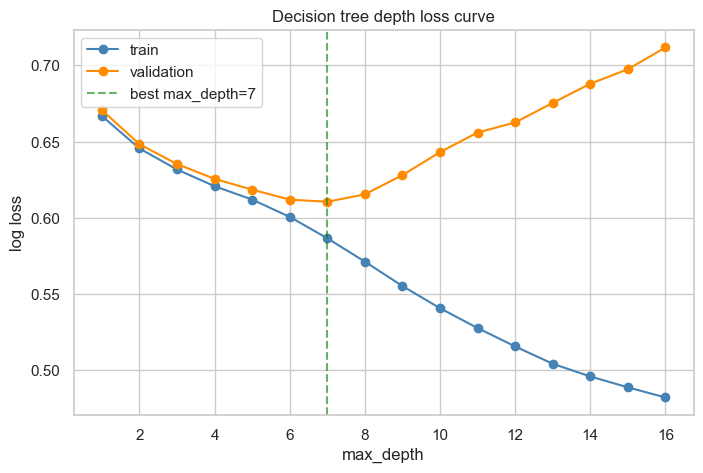

In [5]:
from src.modeling.curves import param_loss_curve
from sklearn.tree import DecisionTreeClassifier

depths = list(range(1, 17))
tr, va = param_loss_curve(
    lambda d: DecisionTreeClassifier(
        max_depth=d, min_samples_leaf=50, class_weight="balanced", random_state=42
    ),
    depths, search.X_train, search.y_train, data.X_holdout, data.y_holdout,
)
plots.plot_param_loss_curve(depths, tr, va, xlabel="max_depth", title="Decision tree depth loss curve")
plt.show()

## CV validation and learning curves

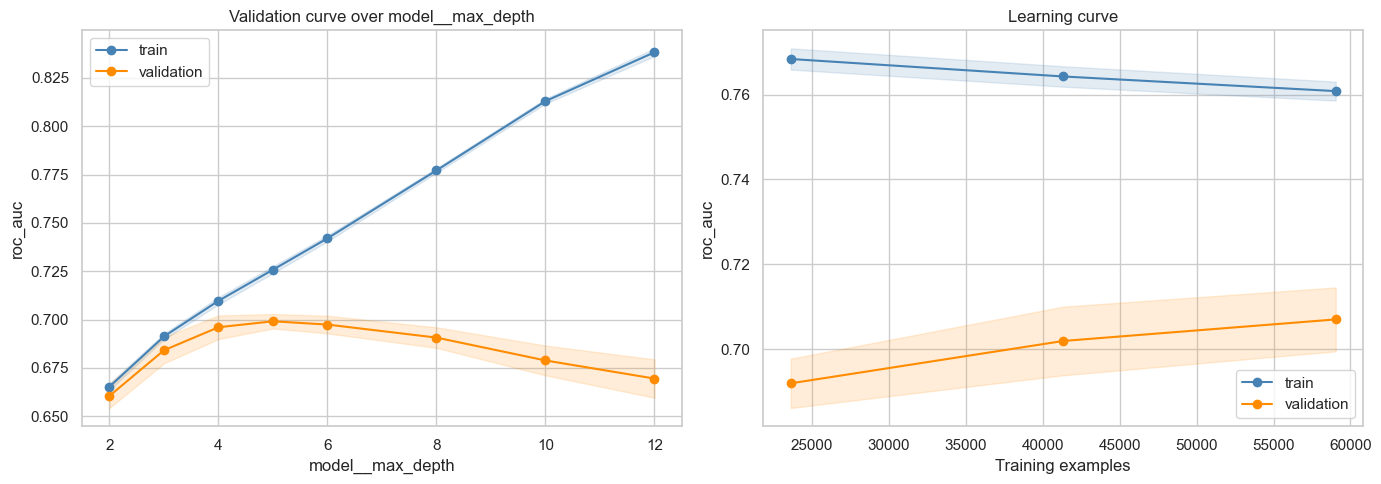

In [6]:
from sklearn.tree import DecisionTreeClassifier

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plots.plot_validation_curve(
    make_pipeline(DecisionTreeClassifier(min_samples_leaf=50, class_weight="balanced", random_state=42)),
    search.X_train, search.y_train,
    param_name="model__max_depth",
    param_range=[2, 3, 4, 5, 6, 8, 10, 12],
    cv=search.cv, ax=axes[0],
)
plots.plot_learning_curve(gs.best_estimator_, search.X_train, search.y_train, cv=search.cv, ax=axes[1], train_sizes=np.linspace(0.4, 1.0, 3))
plt.tight_layout()
plt.show()

## Holdout evaluation

In [7]:
# Train vs holdout metrics for the selected model (overfitting check)
report = train_valid_report(final_model, data, valid_as_holdout=True)
report.round(4)


,roc_auc,gini,ks,pr_auc,log_loss,brier,best_f1,best_f1_threshold
train,0.7470,0.4941,0.3657,0.2209,0.5939,0.2051,0.2907,0.65
holdout,0.7162,0.4325,0.3328,0.1921,0.6084,0.2095,0.2711,0.65


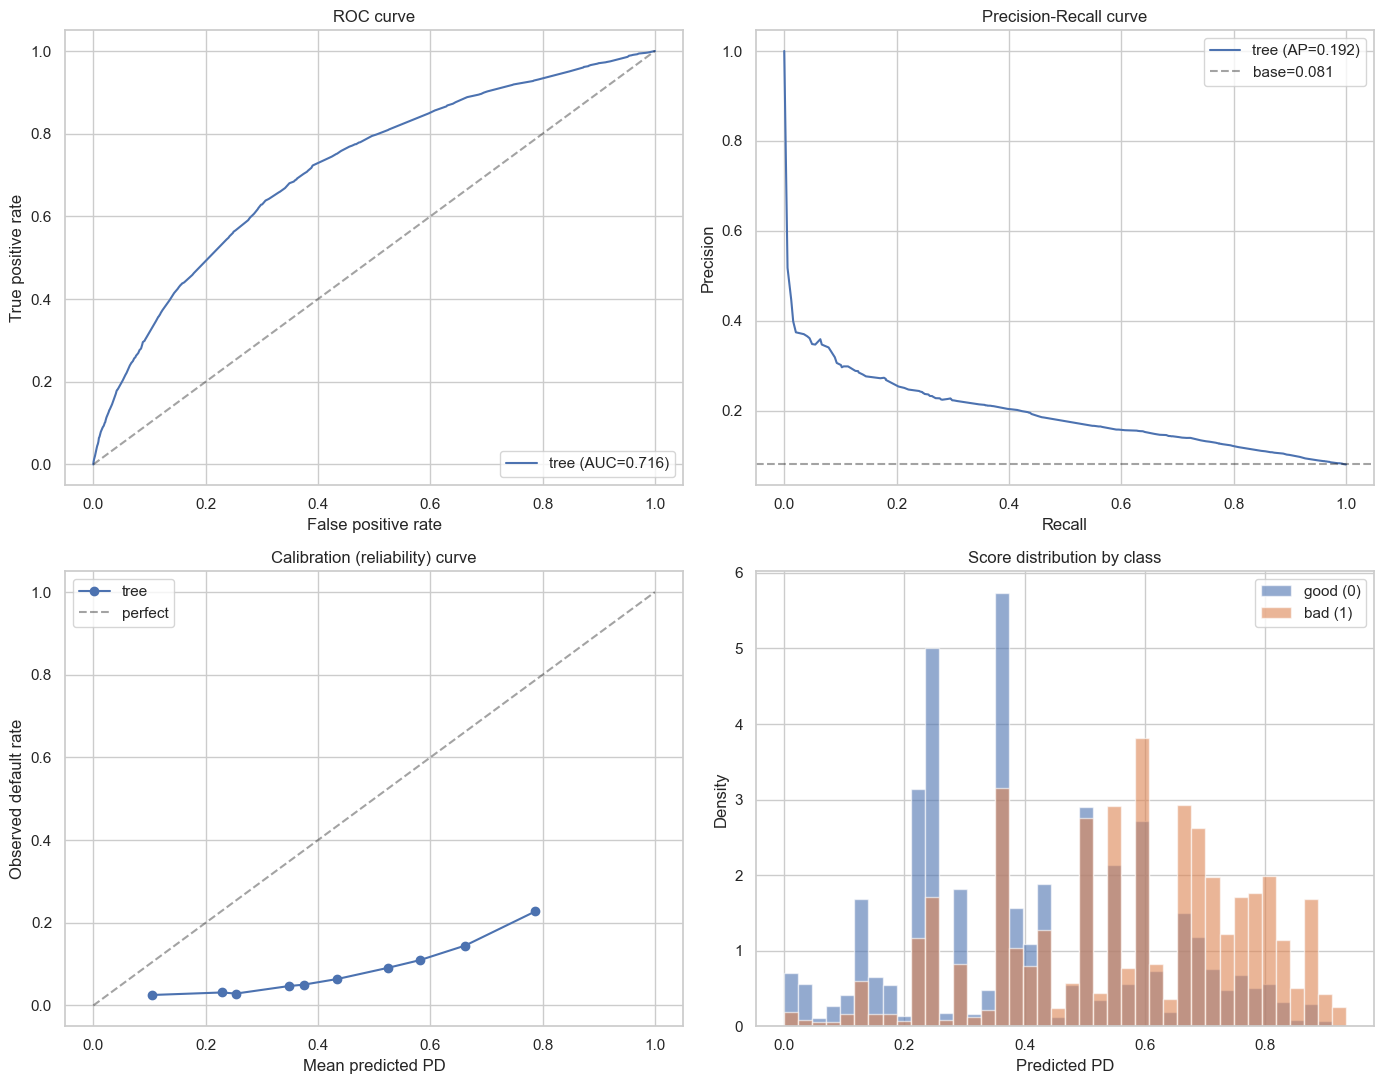

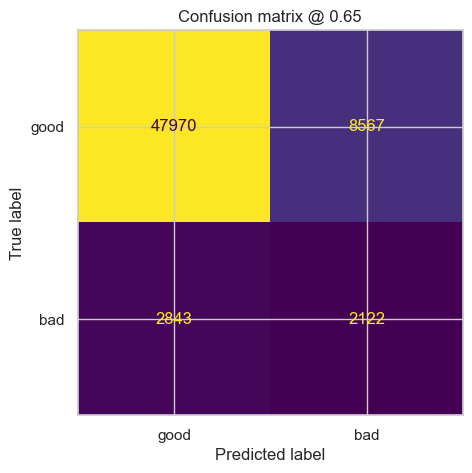

In [8]:
# Holdout diagnostics for the selected model
best = final_model
proba_ho = best.predict_proba(data.X_holdout)[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
plots.plot_roc_pr(data.y_holdout.to_numpy(), proba_ho, label="tree", axes=axes[0])
plots.plot_calibration(data.y_holdout.to_numpy(), proba_ho, ax=axes[1][0], label="tree")
plots.plot_score_distribution(data.y_holdout.to_numpy(), proba_ho, ax=axes[1][1])
plt.tight_layout()
plt.show()

best_t = classification_metrics(data.y_holdout.to_numpy(), proba_ho)["best_f1_threshold"]
fig, ax = plt.subplots(figsize=(5, 5))
plots.plot_confusion(data.y_holdout.to_numpy(), proba_ho, threshold=best_t, ax=ax)
plt.show()


## Feature importance

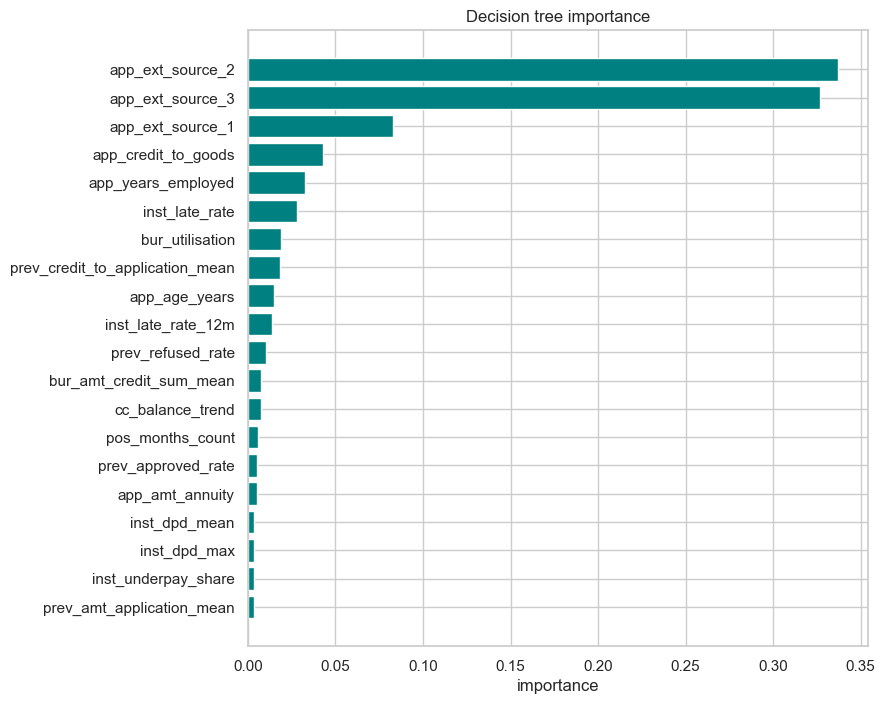

In [9]:
# Feature importance for the selected model
pre = final_model.named_steps["preprocess"]
feat_names = list(pre.transform(search.X_train.iloc[:1]).columns)
model = final_model.named_steps["model"]
importances = getattr(model, "feature_importances_", None)
if importances is not None:
    fig, ax = plt.subplots(figsize=(8, 8))
    plots.plot_feature_importance(feat_names, importances, top=20, ax=ax, title="Decision tree importance")
    plt.show()


## Takeaways

- The depth loss curve shows the overfitting point; CV picks a shallow,
  regularised tree.
- A single tree typically trails logistic regression on AUC but captures
  interactions; ensembles and boosting build on this.